# *Integrantes: Maria Alejandra Villa - Cristhian Bejarano*

# Proyecto MLOps: predicción de churn

## Objetivo del proyecto

Explorar el conjunto de datos de clientes de telecomunicaciones para conocer su estructura, los tipos de variables y la distribución de la variable `Churn`. Este análisis permitirá identificar características relevantes y posibles aspectos de calidad de los datos antes de realizar su preparación y construir modelos predictivos.

El archivo Telco Customer Churn contiene información de clientes de una empresa de telecomunicaciones base de datos tomada de la platarfoma KAggle. Cada fila representa un cliente y `Churn` indica si canceló el servicio (`Yes`) o si permaneció (`No`). Esa columna será nuestro objetivo cuando lleguemos al modelado.


## Descripción del conjunto de datos

El conjunto de datos contiene 7.043 registros de clientes y 21 columnas. Cada fila corresponde a un cliente e incluye información demográfica, servicios contratados, características de su cuenta y cargos.

A continuación, se presenta una tabla descriptiva de las variables que conforman el conjunto de datos, con el propósito de facilitar su comprensión e identificar sus principales características. Esta descripción permitirá establecer una base conceptual para el análisis y tratamiento de los datos a lo largo del desarrollo del proyecto.

## Diccionario de variables

| Variable | Traducción o significado | Tipo observado | Naturaleza |
|---|---|---|---|
| `customerID` | Identificador del cliente | Texto (`str`) | Identificador |
| `gender` | Género del cliente | Texto (`str`) | Categórica |
| `SeniorCitizen` | Indica si el cliente es adulto mayor (0 = no, 1 = sí) | Entero (`int64`) | Categórica binaria |
| `Partner` | Indica si el cliente tiene pareja | Texto (`str`) | Categórica binaria |
| `Dependents` | Indica si el cliente tiene personas dependientes | Texto (`str`) | Categórica binaria |
| `tenure` | Antigüedad del cliente, en meses | Entero (`int64`) | Numérica |
| `PhoneService` | Indica si tiene servicio telefónico | Texto (`str`) | Categórica binaria |
| `MultipleLines` | Indica si tiene varias líneas telefónicas | Texto (`str`) | Categórica |
| `InternetService` | Tipo de servicio de Internet | Texto (`str`) | Categórica |
| `OnlineSecurity` | Indica si tiene seguridad en línea | Texto (`str`) | Categórica |
| `OnlineBackup` | Indica si tiene respaldo en línea | Texto (`str`) | Categórica |
| `DeviceProtection` | Indica si tiene protección para dispositivos | Texto (`str`) | Categórica |
| `TechSupport` | Indica si tiene soporte técnico | Texto (`str`) | Categórica |
| `StreamingTV` | Indica si tiene servicio de televisión en streaming | Texto (`str`) | Categórica |
| `StreamingMovies` | Indica si tiene servicio de películas en streaming | Texto (`str`) | Categórica |
| `Contract` | Tipo de contrato | Texto (`str`) | Categórica |
| `PaperlessBilling` | Indica si recibe facturación electrónica | Texto (`str`) | Categórica binaria |
| `PaymentMethod` | Método de pago | Texto (`str`) | Categórica |
| `MonthlyCharges` | Cargos mensuales del cliente | Decimal (`float64`) | Numérica |
| `TotalCharges` | Cargos totales acumulados del cliente | Texto (`str`) | Numérica en significado; almacenada como texto |
| `Churn` | Indica si el cliente abandonó el servicio | Texto (`str`) | Categórica binaria; variable objetivo |

## 1.Carga del Dataset para su análisis

In [1]:
from pathlib import Path

import pandas as pd

csv_path = Path.cwd() / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not csv_path.is_file():
    raise FileNotFoundError(f"No se encontró el CSV de origen: {csv_path}")

df = pd.read_csv(csv_path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## 1.1. Estructura y tipos de variables

El conjunto de datos contiene 7.043 filas y 21 columnas. Según `df.info()`, 18 columnas están almacenadas como texto (`str`), dos como enteros (`int64`) y una como decimal (`float64`).

Estos tipos describen cómo pandas almacena los datos, pero no siempre representan su significado. Por ejemplo, `SeniorCitizen` está almacenada como número, aunque sus valores identifican dos categorías. `TotalCharges`, por su parte, representa cargos, pero aparece almacenada como texto; se revisará con más detalle antes de decidir si necesita algún tratamiento.

Aunque en la revisión inicial del conjunto de datos (dataset) no se identifican valores nulos, durante el análisis de calidad de los datos se realizará una verificación específica para confirmar esta condición y garantizar la integridad de la información utilizada en el proyecto.

## 2. Calidad de los datos

### 2.1. Registros duplicados

Se revisará si existen filas completamente duplicadas en el conjunto de datos.

In [4]:
print("El numero de columnas duplicadas son: {0}".format(df.duplicated().sum()))
print("El numero de clientes duplicados son: {0}".format(df.duplicated(subset=['customerID']).sum()))
print("El numero de valores nulos son: {0}".format(df.isna().sum().sum()))
(df["TotalCharges"].str.strip() == "").sum()


El numero de columnas duplicadas son: 0
El numero de clientes duplicados son: 0
El numero de valores nulos son: 0


np.int64(11)

In [5]:
df.loc[
    df["TotalCharges"].str.strip().eq(""),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Se identificaron 11 valores vacíos en `TotalCharges`. En los 11 registros, `tenure` es 0 y `Churn` es `No`; esto es consistente con clientes recién incorporados que aún no acumulan cargos totales. Se conservarán sin cambios durante este análisis exploratorio.

In [6]:
print("Verificación de clientes que no abandonaron y clientes que abandonaron")
print("--"*50)
df["Churn"].value_counts()

Verificación de clientes que no abandonaron y clientes que abandonaron
----------------------------------------------------------------------------------------------------


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [7]:
df["Churn"].value_counts(normalize=True).mul(100).round(2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

El 73,46 % de los clientes no abandonó el servicio, mientras que el 26,54 % sí lo hizo. Esta diferencia entre las categorías se tendrá en cuenta para comparar los resultados reales con las predicciones del modelo durante el entrenamiento.


### 2.2. Distribución de variables numéricas

In [8]:
df[["tenure", "MonthlyCharges"]].describe().round(2)

,tenure,MonthlyCharges
count,7043.00,7043.00
mean,32.37,64.76
std,24.56,30.09
min,0.00,18.25
25%,9.00,35.50
50%,29.00,70.35
75%,55.00,89.85
max,72.00,118.75


La antigüedad promedio de los clientes es de 32,37 meses, mientras que la mediana es de 29 meses. La mitad de los clientes tiene una antigüedad de hasta 29 meses y el 75 % tiene hasta 55 meses.

Los cargos mensuales tienen un promedio de 64,76 y una mediana de 70,35. La mitad de los clientes paga hasta 70,35 y el 75 % paga hasta 89,85. Los valores observados van de 18,25 a 118,75.

### 2.3. Distribución de variables categóricas

In [9]:
variables_categoricas = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod"
]

resumen_categoricas = pd.concat(
    [
        df[col].value_counts().rename_axis("Categoria")
        .reset_index(name="Frecuencia")
        .assign(Variable=col)
        for col in variables_categoricas
    ],
    ignore_index=True
)

resumen_categoricas["Porcentaje"] = (
    resumen_categoricas["Frecuencia"] / len(df) * 100
).round(2)

resumen_categoricas[["Variable", "Categoria", "Frecuencia", "Porcentaje"]]

,Variable,Categoria,Frecuencia,Porcentaje
0,gender,Male,3555,50.48
1,gender,Female,3488,49.52
2,SeniorCitizen,0,5901,83.79
3,SeniorCitizen,1,1142,16.21
4,Partner,No,3641,51.70
5,Partner,Yes,3402,48.30
6,Dependents,No,4933,70.04
7,Dependents,Yes,2110,29.96
8,PhoneService,Yes,6361,90.32
9,PhoneService,No,682,9.68


En las variables categóricas, la categoría más frecuente de contrato es `Month-to-month` (55,02 %). El servicio de Internet más común es `Fiber optic` (43,96 %). El 59,22 % de los clientes tiene facturación electrónica y el método de pago más frecuente es `Electronic check` (33,58 %). Las categorías `No internet service` y `No phone service` describen servicios que el cliente no tiene; no son valores faltantes.e.

### 2.4. Relacion entre variables vs variable objetivo

In [10]:
variables_relacion = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport"
]

resumen_churn = pd.concat(
    {
        variable: pd.crosstab(
            df[variable],
            df["Churn"],
            normalize="index"
        ).mul(100).round(2)
        for variable in variables_relacion
    },
    names=["Variable"]
)

resumen_churn

Churn                                         No    Yes
Variable                                               
Contract        Month-to-month             57.29  42.71
                One year                   88.73  11.27
                Two year                   97.17   2.83
InternetService DSL                        81.04  18.96
                Fiber optic                58.11  41.89
                No                         92.60   7.40
PaymentMethod   Bank transfer (automatic)  83.29  16.71
                Credit card (automatic)    84.76  15.24
                Electronic check           54.71  45.29
                Mailed check               80.89  19.11
TechSupport     No                         58.36  41.64
                No internet service        92.60   7.40
                Yes                        84.83  15.17

### 2.5. Relación entre variables y abandono

La proporción de abandono es mayor entre los clientes con contrato mensual (42,71 %) que entre quienes tienen contrato anual (11,27 %) o de dos años (2,83 %). También es más alta entre los clientes con fibra óptica (41,89 %) y entre quienes pagan con cheque electrónico (45,29 %).

Para `TechSupport`, el abandono es de 41,64 % entre quienes no tienen soporte técnico y de 15,17 % entre quienes sí lo tienen. Estos resultados muestran asociaciones en los datos, pero no demuestran que esas características causen el abandono.

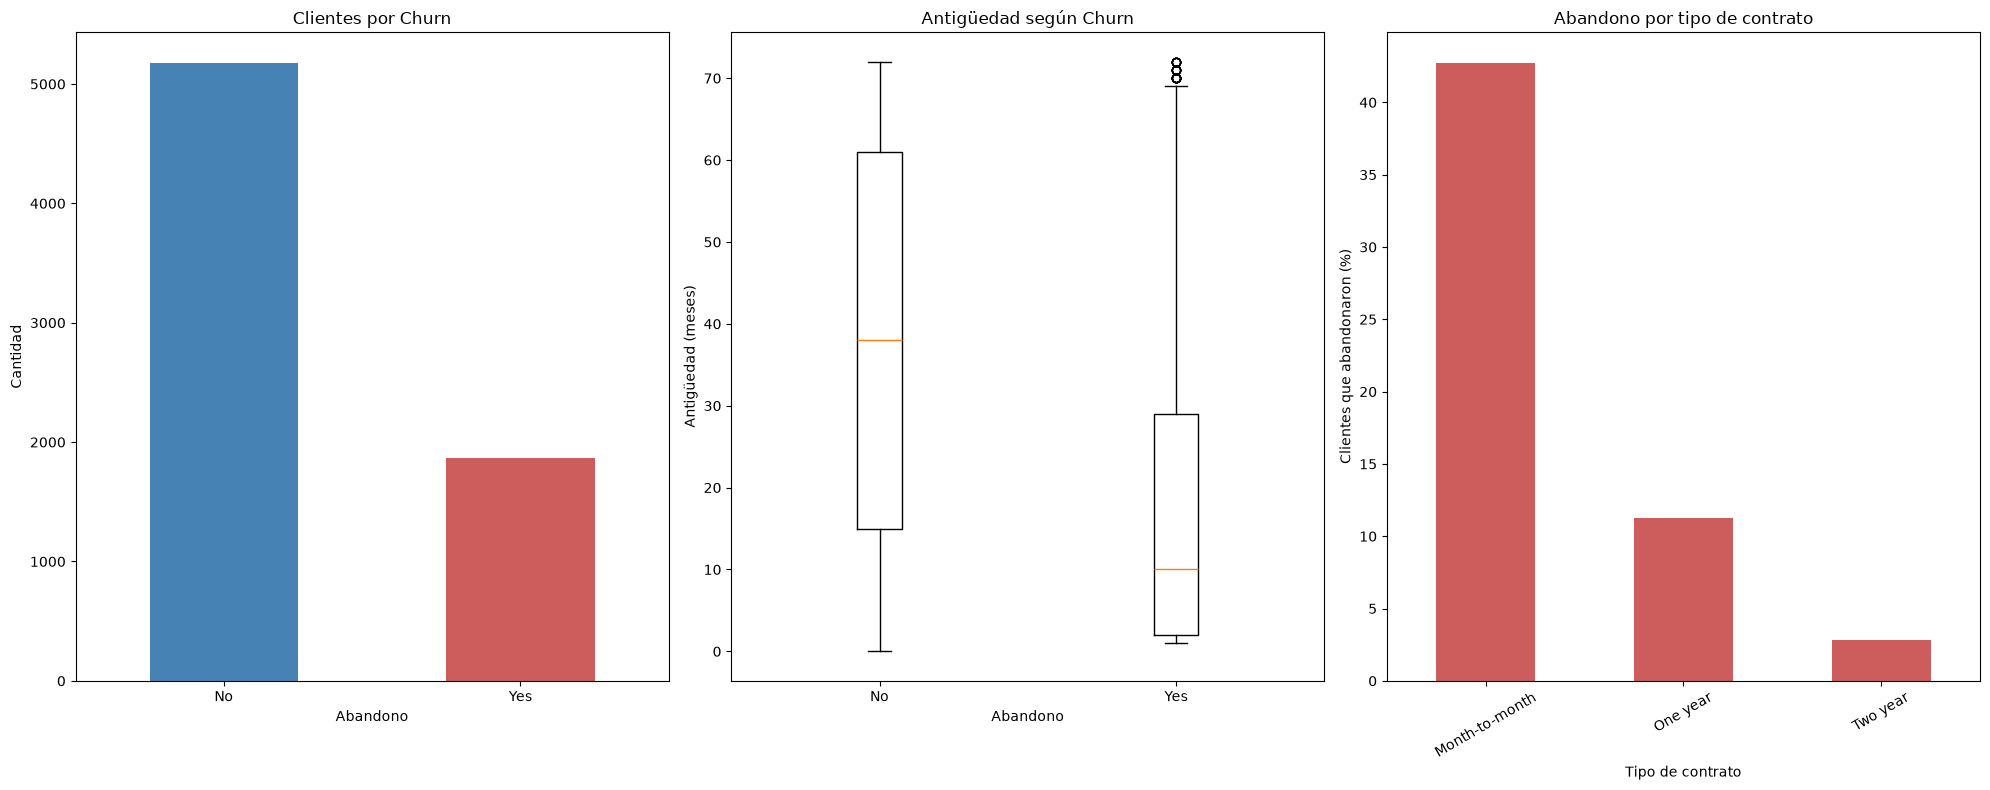

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# Cantidad de clientes por categoría de Churn
df["Churn"].value_counts().reindex(["No", "Yes"]).plot(
    kind="bar", ax=axes[0], color=["steelblue", "indianred"]
)
axes[0].set_title("Clientes por Churn")
axes[0].set_xlabel("Abandono")
axes[0].set_ylabel("Cantidad")
axes[0].tick_params(axis="x", rotation=0)

# Antigüedad del cliente según Churn
datos_tenure = [
    df.loc[df["Churn"] == categoria, "tenure"]
    for categoria in ["No", "Yes"]
]
axes[1].boxplot(datos_tenure, tick_labels=["No", "Yes"])
axes[1].set_title("Antigüedad según Churn")
axes[1].set_xlabel("Abandono")
axes[1].set_ylabel("Antigüedad (meses)")

# Porcentaje de abandono por tipo de contrato
abandono_contrato = (
    pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"] * 100
).reindex(["Month-to-month", "One year", "Two year"])

abandono_contrato.plot(
    kind="bar", ax=axes[2], color="indianred"
)
axes[2].set_title("Abandono por tipo de contrato")
axes[2].set_xlabel("Tipo de contrato")
axes[2].set_ylabel("Clientes que abandonaron (%)")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

La distribución de `Churn` muestra que hay más clientes que permanecieron en el servicio (`No`) que clientes que lo abandonaron (`Yes`). En el diagrama de cajas, los clientes que abandonaron presentan una antigüedad menor que quienes permanecieron. Además, el porcentaje de abandono es más alto entre quienes tienen contrato mensual que entre quienes tienen contratos de uno o dos años. Estas observaciones describen asociaciones y no implican causalidad.

## 3. Conclusiones del análisis exploratorio

El conjunto de datos contiene 7.043 clientes y 21 variables. No se encontraron filas duplicadas ni identificadores de cliente repetidos. Aunque pandas no detectó valores nulos con `isna()`, se identificaron 11 valores vacíos en `TotalCharges`; corresponden a registros con `tenure` igual a 0 y `Churn` igual a `No`.

El 26,54 % de los clientes abandonó el servicio. La proporción de abandono observada es mayor entre clientes con contrato mensual, clientes con fibra óptica, quienes pagan con cheque electrónico y quienes no tienen soporte técnico. Además, en los gráficos, quienes abandonaron muestran menor antigüedad que quienes permanecieron.

Estos resultados son descriptivos: muestran patrones y asociaciones en este conjunto de datos, pero no permiten concluir que una característica cause el abandono. `TotalCharges` está almacenada como texto y deberá revisarse durante la preparación de los datos.